# Iris classification: Decision Trees and Random Forests

**Purpose:** turn the Iris example into a compact revision notebook. The emphasis is on understanding what each stage does, why it is needed, and the mathematics behind the main calculations.

## Learning objectives

By the end, you should be able to:

1. distinguish features (`X`) from the target (`y`);
2. explain why we split data into training and test sets;
3. explain how a decision tree chooses splits using impurity;
4. fit a decision tree and evaluate its predictions;
5. explain how a random forest combines many trees; and
6. interpret impurity-based feature importance without treating it as causation.

## Workflow

`inspect data → explore data → define X and y → split → fit → predict → evaluate → interpret`

> **Important comparison with the R book:** this notebook uses scikit-learn. Its `DecisionTreeClassifier` is a CART-style tree; it is not algorithmically identical to `party::ctree()` (a conditional-inference tree). The scikit-learn and R random-forest implementations also have implementation and default-setting differences. The goal here is to learn the same broad modeling workflow in idiomatic Python, not to reproduce identical numerical results.

## 1. Load and inspect the data

The Iris dataset contains **150 flower observations**, with four numerical measurements and one categorical target (`species`). There are 50 observations for each of three species: setosa, versicolor, and virginica.

| Role | Column | Meaning |
|---|---|---|
| Feature | `sepal_length` | Sepal length |
| Feature | `sepal_width` | Sepal width |
| Feature | `petal_length` | Petal length |
| Feature | `petal_width` | Petal width |
| Target | `species` | Flower species to predict |

A row is one observation (one flower); a column is one variable (one measurement or the target).

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the Iris dataset as a pandas DataFrame.
iris = sns.load_dataset("iris")

# info() prints data types and non-missing counts; it returns None,
# so call it directly rather than wrapping it in display().
iris.info()

# Summary statistics for the numerical columns.
display(iris.describe())

# Preview the first five observations.
display(iris.head())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### What should we check?

- **Shape:** 150 rows and 5 columns.
- **Data types:** four numerical measurements and one categorical species column.
- **Missing values:** check the non-null counts from `info()`.
- **Target balance:** each species should have 50 observations.

`describe()` summarizes numerical distributions (count, mean, standard deviation, quartiles, minimum, and maximum). These summaries help us understand the data before fitting a model; they do not train a model.

In [2]:
print("Dataset shape:", iris.shape)
print("\nSpecies counts:")
display(iris["species"].value_counts())

Dataset shape: (150, 5)

Species counts:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## 2. Explore the measurements visually

### Boxplot: one feature grouped by species

A boxplot summarizes a variable's distribution by group. Here, it lets us compare sepal length across the three species.

The box shows the interquartile range (25th to 75th percentile), the line inside is the median, and whiskers/outliers show additional distribution information under the plotting convention.

This is exploratory analysis: we are looking for patterns and overlap, not making model predictions yet.

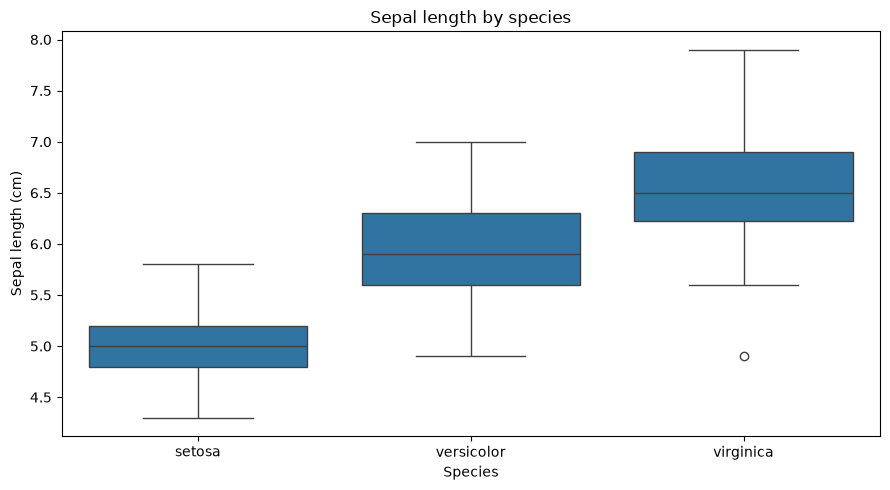

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(data=iris, x="species", y="sepal_length", ax=ax)
ax.set(title="Sepal length by species", xlabel="Species", ylabel="Sepal length (cm)")

plt.tight_layout()
plt.show()

### Pair plot: pairwise relationships

A pair plot creates a grid of plots for every pair of numerical features:

- off-diagonal cells are scatterplots comparing two features;
- diagonal cells show the individual distribution of one feature;
- `hue="species"` colors observations by species.

With four numerical features, the grid has **4 × 4 = 16 panels**. It helps us see relationships, clusters, and which measurements may separate species. `pairplot()` is a Seaborn *figure-level* function: it creates and manages its own grid, rather than drawing into an Axes supplied to `plt.subplots()`.

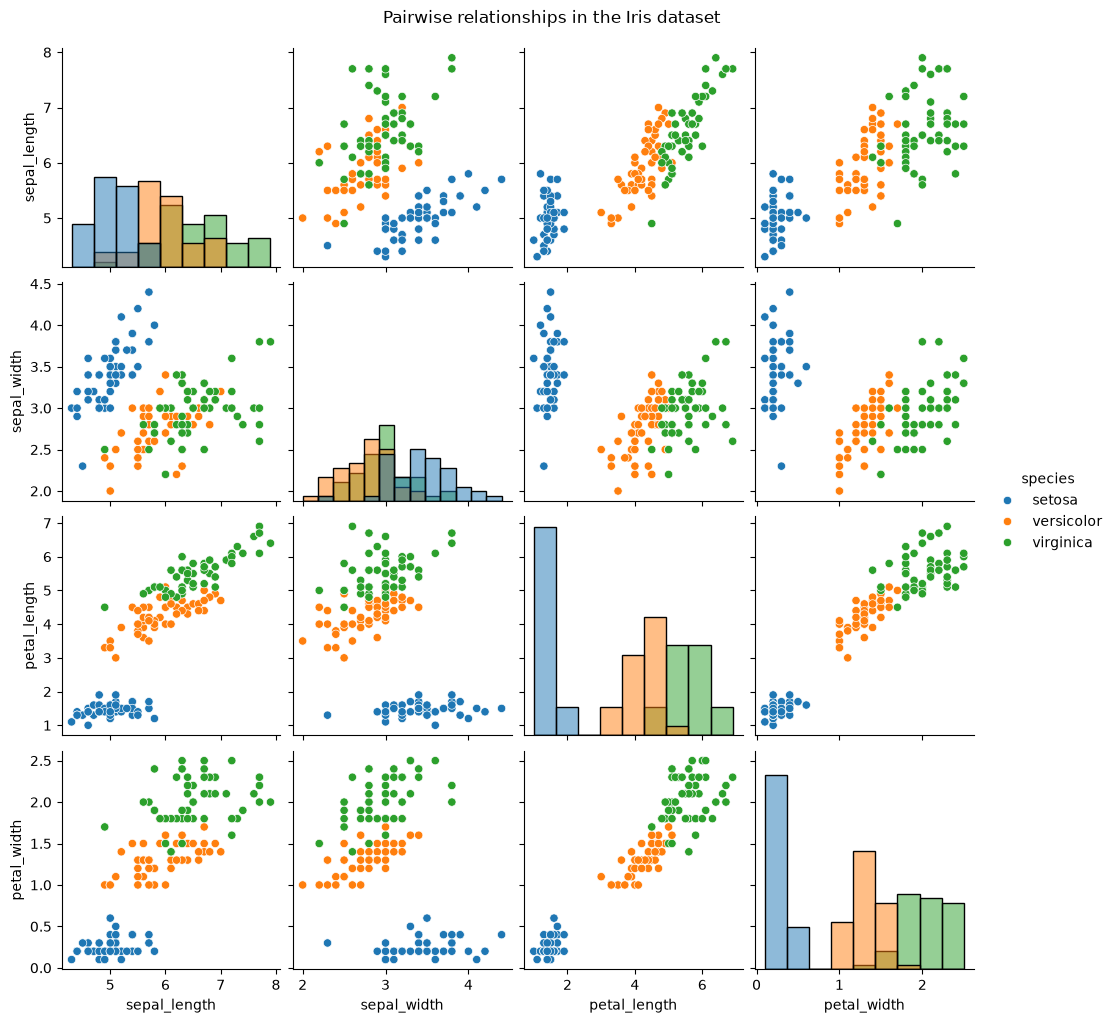

In [4]:
g = sns.pairplot(data=iris, hue="species", diag_kind="hist")
g.fig.suptitle("Pairwise relationships in the Iris dataset", y=1.02)
plt.show()

## 3. Define the prediction problem: features and target

We want to predict a flower's species from its four measurements.

- **`X` (features / predictors):** the information given to the model.
- **`y` (target / label):** the answer the model is learning to predict.

In notation, supervised learning tries to learn a mapping:

$$
 f: X \longrightarrow y
$$

For a new flower, we provide its four measurements and ask the fitted model to estimate its species. We remove `species` from `X` so that the model cannot simply read the answer from an input column (target leakage).

In [5]:
# X contains the four measurements; y contains the species labels.
X = iris.drop(columns="species")
y = iris["species"]

print("X shape (observations, features):", X.shape)
print("y shape (observations,):", y.shape)

X shape (observations, features): (150, 4)
y shape (observations,): (150,)


## 4. Split into training and test sets

We need two distinct sets because we want to evaluate the model on observations it did **not** use to learn its decision rules.

- **Training set:** used by `.fit()` to learn patterns.
- **Test set:** held aside until evaluation; used to estimate performance on unseen observations.

We use a 70/30 split. With 150 observations:

$$
N_{train}=150\times0.70=105
$$

$$
N_{test}=150\times0.30=45
$$

### What the arguments mean

- `test_size=0.30`: allocate 30% to the test set; the remaining 70% goes to training.
- `random_state=1234`: make the randomized split reproducible. The number itself has no special statistical meaning.
- `stratify=y`: preserve the target-class proportions in both sets. Since Iris has 50 examples per species, the split has 35 of each species in training and 15 of each species in testing.

This differs from the book's R expression `sample(2, nrow(iris), replace=TRUE, prob=c(0.7, 0.3))`: that expression independently assigns each row a train/test label, so the resulting counts are random rather than fixed. `train_test_split()` shuffles and partitions the rows into requested sizes. With `stratify=y`, it also preserves class proportions.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=1234,
    stratify=y
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

print("\nSpecies counts in training set:")

display(y_train.value_counts())

print("Species counts in test set:")
display(y_test.value_counts())

Training observations: 105
Test observations: 45

Species counts in training set:


species
virginica     35
setosa        35
versicolor    35
Name: count, dtype: int64

Species counts in test set:


species
virginica     15
setosa        15
versicolor    15
Name: count, dtype: int64

### Why pass `X` and `y` together?

Each flower's measurements must stay paired with its correct species label. Passing both arrays/DataFrames to `train_test_split()` makes scikit-learn apply the same split to both, so the rows remain aligned.

The test set must not be used to fit the model or choose its settings. Doing so would leak test information into the modeling process and make the final evaluation too optimistic.

## 5. Decision Tree: the intuition

A decision tree makes predictions by asking a sequence of feature-based questions, such as:

- Is `petal_length` less than or equal to a threshold?
- Depending on the answer, is `petal_width` less than or equal to another threshold?

Each question divides the observations into child nodes. The algorithm prefers splits that create child groups containing more homogeneous target classes.

**Impurity** measures how mixed the classes are inside a node:

- a node containing only one species is pure (impurity = 0);
- a node containing a mixture of species has higher impurity.

For classification trees, common impurity measures are Gini impurity and entropy.

### Gini impurity: formula and hand calculation

For a node containing $K$ classes, Gini impurity is:

$$
G=1-\sum_{k=1}^{K}p_k^2
$$

Here, $p_k$ is the proportion of observations in class $k$ within **that node**.

**Worked example (illustrative, not a claim about a particular Iris split):** imagine a node contains 10 flowers: 5 setosa, 3 versicolor, and 2 virginica.

$$
p=(0.5,\,0.3,\,0.2)
$$

$$
G=1-(0.5^2+0.3^2+0.2^2)
$$

$$
G=1-(0.25+0.09+0.04)=0.62
$$

If all 10 flowers belonged to one species, the proportions would be $(1,0,0)$, so:

$$
G=1-(1^2+0^2+0^2)=0
$$

For three classes, the maximum Gini impurity occurs when all classes are equally represented:

$$
G_{max}=1-3\left(\frac{1}{3}\right)^2=\frac{2}{3}\approx0.667
$$

So, for this three-class problem, lower Gini means a purer node.

### How does a split reduce impurity?

A candidate split creates a left child and a right child. The tree calculates their **weighted average impurity**:

$$
G_{after}=\frac{N_L}{N}G_L+\frac{N_R}{N}G_R
$$

where $N$ is the parent-node size, $N_L,N_R$ are child sizes, and $G_L,G_R$ are child impurities.

Using the illustrative 10-flower parent above, imagine a split produces:

- left child: 5 setosa only, so $G_L=0$;
- right child: 3 versicolor and 2 virginica, so

$$
G_R=1-(0.6^2+0.4^2)=0.48
$$

The weighted impurity after the split is:

$$
G_{after}=\frac{5}{10}(0)+\frac{5}{10}(0.48)=0.24
$$

The impurity reduction (often called impurity decrease or Gini gain) is:

$$
\Delta G=G_{parent}-G_{after}=0.62-0.24=0.38
$$

A larger reduction means that candidate split made the child nodes purer. The tree searches across candidate features and thresholds and chooses a split that gives a strong reduction.

### Entropy: another impurity measure

Entropy measures class mixture using logarithms:

$$
H=-\sum_{k=1}^{K}p_k\log_2(p_k)
$$

For the same proportions $(0.5,0.3,0.2)$:

$$
H=-[0.5\log_2(0.5)+0.3\log_2(0.3)+0.2\log_2(0.2)]
$$

$$
H\approx1.485\text{ bits}
$$

A pure node has entropy 0. For three equally represented classes, maximum entropy is:

$$
H_{max}=\log_2(3)\approx1.585
$$

Gini and entropy both measure impurity, but their numerical scales differ. This notebook explicitly chooses `criterion="gini"`, so the tree uses Gini to evaluate candidate splits. Entropy is an alternative criterion; it is not being used in this model.

### Create and fit the Decision Tree

`DecisionTreeClassifier(...)` creates/configures a model object; it does **not** learn from the data yet.

- `criterion="gini"`: use Gini impurity to evaluate splits.
- `max_depth=4`: limit the tree's depth to reduce complexity and help control overfitting. A deeper tree can create very specific rules that fit the training set but generalize poorly.
- `random_state=1234`: make randomized choices reproducible.

Then `.fit(X_train, y_train)` performs the learning: the algorithm searches for feature/threshold splits using the training measurements and their known species labels.

In [7]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Create/configure the model.
dt_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=1234,
    max_depth=4
)

# Learn the tree structure from the training data.
dt_model.fit(X_train, y_train)

print("Tree depth:", dt_model.get_depth())
print("Number of leaves:", dt_model.get_n_leaves())

Tree depth: 4
Number of leaves: 6


### Visualize and read the fitted tree

`plot_tree()` draws the learned tree. It is a visualization of the model **after fitting**.

- `feature_names=X.columns`: show meaningful feature names instead of `x[0]`, `x[1]`, etc.
- `class_names=dt_model.classes_`: show the species labels in the model's class order.
- `filled=True`: color nodes by their predicted class, with color intensity reflecting class purity.

Typical node fields:

- `petal_width <= 0.8`: the split rule at that node;
- `gini`: impurity among training observations reaching the node;
- `samples`: number of training observations reaching the node;
- `value`: class counts at that node, in `dt_model.classes_` order;
- `class`: the node's predicted class (the most represented class).

The displayed `samples` and `value` describe the **training data that reached the node**, not the test set.

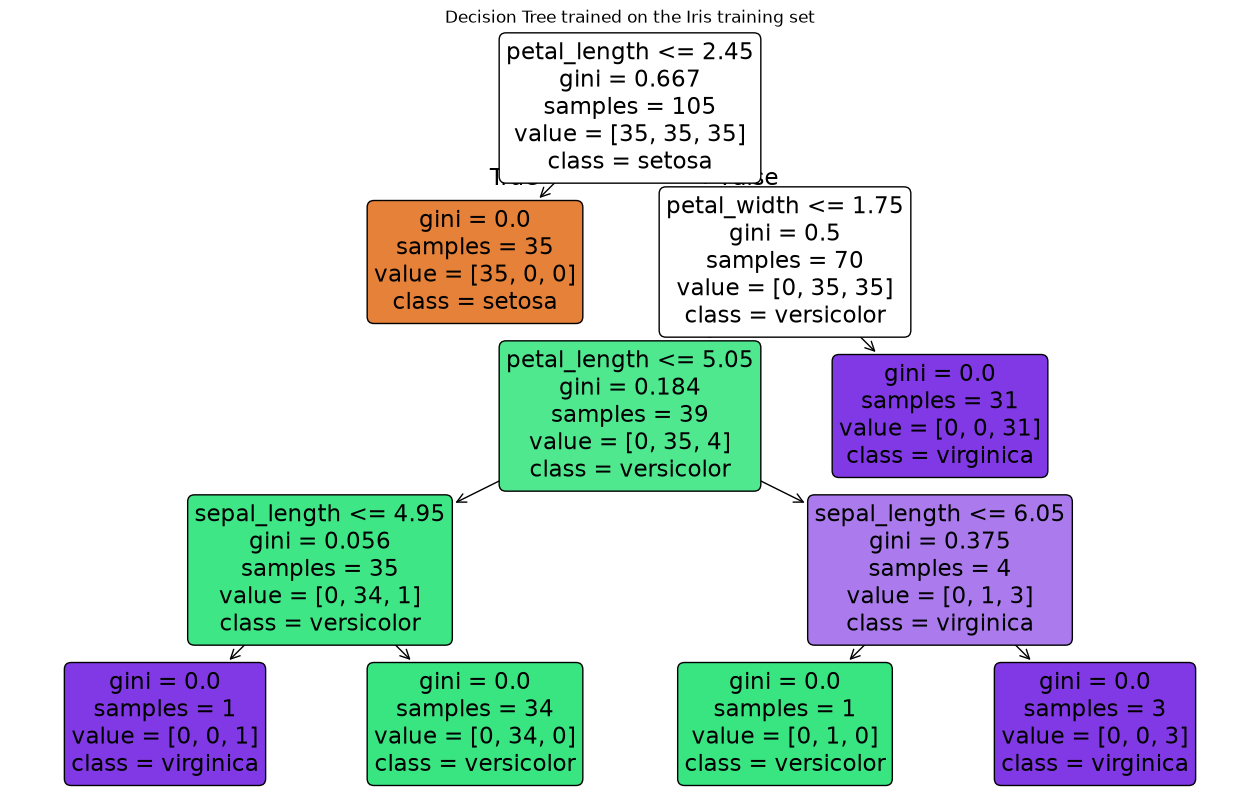

In [8]:
fig, ax = plt.subplots(figsize=(16, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    proportion=False,
    ax=ax
)

ax.set_title("Decision Tree trained on the Iris training set")
plt.show()

### Predict on the held-out test set

After fitting, `.predict(X_test)` sends each test flower through the learned tree and returns a predicted species. It does **not** use `y_test` to make the prediction; `y_test` is kept aside as the answer key for evaluation.

In the R book, the analogous operation is `predict(iris_ctree, newdata = testData)`. The workflow is the same, although the tree algorithms are not identical.

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

dt_predictions = dt_model.predict(X_test)

print("First 10 predictions:", dt_predictions[:10].tolist())
print("First 10 actual labels:", y_test.iloc[:10].tolist())

First 10 predictions: ['virginica', 'virginica', 'virginica', 'setosa', 'virginica', 'setosa', 'setosa', 'virginica', 'versicolor', 'setosa']
First 10 actual labels: ['virginica', 'virginica', 'virginica', 'setosa', 'virginica', 'setosa', 'setosa', 'versicolor', 'versicolor', 'setosa']


### Evaluate: accuracy and confusion matrix

**Accuracy** is the fraction of test observations classified correctly:

$$
\text{Accuracy}=\frac{\text{number of correct predictions}}{\text{number of test observations}}
$$

For a multiclass confusion matrix, the diagonal contains correct predictions. Off-diagonal cells show which actual classes were mistaken for which predicted classes.

In scikit-learn, `confusion_matrix(y_test, predictions)` uses **rows = actual classes** and **columns = predicted classes**. We set the label order explicitly so the table is easy to read.

For comparison, the book uses `table(testPred, testData$Species)`, where rows are predicted and columns are actual. Its table is transposed relative to scikit-learn's default orientation.

In [10]:
dt_accuracy = accuracy_score(y_test, dt_predictions)
print(f"Decision Tree accuracy: {dt_accuracy:.3f} ({dt_accuracy:.1%})")

labels = dt_model.classes_
dt_cm = confusion_matrix(y_test, dt_predictions, labels=labels)

display(pd.DataFrame(
    dt_cm,
    index=pd.Index(labels, name="Actual"),
    columns=pd.Index(labels, name="Predicted")
))

print("\nClassification report:")
print(classification_report(y_test, dt_predictions, zero_division=0))

Decision Tree accuracy: 0.933 (93.3%)


Predicted,setosa,versicolor,virginica
Actual,,,
setosa,15,0,0
versicolor,0,13,2
virginica,0,1,14



Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.93      0.87      0.90        15
   virginica       0.88      0.93      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



**Manual accuracy check:** add the diagonal entries of the confusion matrix, then divide by the total number of test observations. For example, if the diagonal were 14, 13, and 14 in a 45-observation test set:

$$
\text{Accuracy}=\frac{14+13+14}{45}=\frac{41}{45}\approx0.911
$$

This is an illustration of the calculation; use the matrix printed above for this notebook's actual result. Accuracy is a useful summary, while the confusion matrix shows the pattern of errors. Precision, recall, and F1-score (shown in the classification report) provide additional class-specific views.

## 6. Random Forest: the intuition

A Random Forest is an **ensemble**: instead of depending on one decision tree, it builds many trees and aggregates their predictions.

The trees are made different using two main sources of randomness:

1. **Bootstrap sampling:** each tree is trained on a random sample of the training observations drawn *with replacement*. Some training rows may appear more than once in a tree's bootstrap sample, while some may be left out of that sample.
2. **Random feature selection:** at each split, the tree considers a random subset of the available features. In scikit-learn's classifier, the default is `max_features="sqrt"`; with four features, this is approximately two candidate features at each split.

For classification, the forest aggregates the trees' class predictions. More precisely, scikit-learn averages the trees' predicted class probabilities and selects the class with the highest average probability. This is commonly described as voting.

Why use many diverse trees? A single tree can be sensitive to the particular training sample. Aggregating many different trees often reduces this instability (variance) and improves generalization, although it does not guarantee better results on every dataset.

### Create and fit the Random Forest

- `n_estimators=100`: build 100 decision trees.
- `random_state=1234`: make the randomization reproducible.

The `.fit(X_train, y_train)` call trains the forest using the same training set as the single decision tree. Keeping the split the same makes the model comparison fairer.

The R book's corresponding argument is `ntree=100`. The broad meaning is the same: build 100 trees. The book also sets `proximity=TRUE`, which requests an additional proximity matrix; this notebook does not request that optional output.

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=1234
)

rf_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1234
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap boots

### Predict and evaluate the Random Forest

The evaluation is the same as for the Decision Tree: predict the held-out test features, compare predictions with the true test labels, and inspect the confusion matrix.

The difference is the model making the predictions: the forest aggregates information from its 100 trees.

In [12]:
rf_predictions = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)
print(f"Random Forest accuracy: {rf_accuracy:.3f} ({rf_accuracy:.1%})")

rf_cm = confusion_matrix(y_test, rf_predictions, labels=rf_model.classes_)
display(pd.DataFrame(
    rf_cm,
    index=pd.Index(rf_model.classes_, name="Actual"),
    columns=pd.Index(rf_model.classes_, name="Predicted")
))

print("\nClassification report:")
print(classification_report(y_test, rf_predictions, zero_division=0))

Random Forest accuracy: 0.956 (95.6%)


Predicted,setosa,versicolor,virginica
Actual,,,
setosa,15,0,0
versicolor,0,14,1
virginica,0,1,14



Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.93      0.93      0.93        15
   virginica       0.93      0.93      0.93        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



### Compare the two models

Both models were trained and evaluated using the same training/test split. Compare their test accuracy and confusion matrices, but do not conclude that one model is universally better from one small split.

A single decision tree is easier to inspect and explain. A random forest is less transparent because it combines many trees, but often improves stability by averaging across them. For a robust model comparison, use cross-validation on the training data and keep the test set for final evaluation.

In [13]:
model_comparison = pd.DataFrame(
    {
        "Model": ["Decision Tree", "Random Forest"],
        "Test accuracy": [dt_accuracy, rf_accuracy]
    }
).set_index("Model")

display(model_comparison)

,Test accuracy
Model,
Decision Tree,0.933333
Random Forest,0.955556


## 7. Feature importance in the Random Forest

Feature importance asks: **which input features contributed most to the forest's impurity reductions?** It is not a measure of causal influence, and it is not the same as accuracy.

Scikit-learn's `feature_importances_` uses **mean decrease in impurity** (also called impurity-based or Gini importance for this classifier). At a tree node, a split's weighted impurity decrease is:

$$
\text{decrease at node} = \frac{N_t}{N}
\left[I_t-\frac{N_L}{N_t}I_L-\frac{N_R}{N_t}I_R\right]
$$

where:

- $N$ is the number of training observations used by the tree;
- $N_t$ is the number reaching the node;
- $I_t$ is the node's impurity before splitting;
- $N_L,N_R$ and $I_L,I_R$ describe its child nodes.

The model adds the weighted impurity decreases for splits using a feature, aggregates across the forest, and normalizes the scores. The resulting scikit-learn feature importances sum to 1 (apart from possible tiny floating-point differences).

**Interpretation:** a larger score means that feature was more useful to this fitted forest for reducing impurity. It does not mean the feature causes the species, nor does it prove that the feature would be equally important in another sample or model.

### Extract, rank, and plot feature importance

- `rf_model.feature_importances_` returns one normalized importance score per feature, in the same order as the model's input columns.
- `pd.Series(..., index=X.columns)` attaches readable feature names to those scores.
- `sort_values()` ranks them.
- A horizontal bar chart makes the ranking easier to read.

The R book reports `MeanDecreaseGini` with `importance(rf)` and plots it using `varImpPlot(rf)`. The broad interpretation is similar, but the numerical scales and implementation details differ, so do not compare the raw R and Python numbers directly.

,Importance
petal_width,0.443182
petal_length,0.425114
sepal_length,0.110902
sepal_width,0.020803


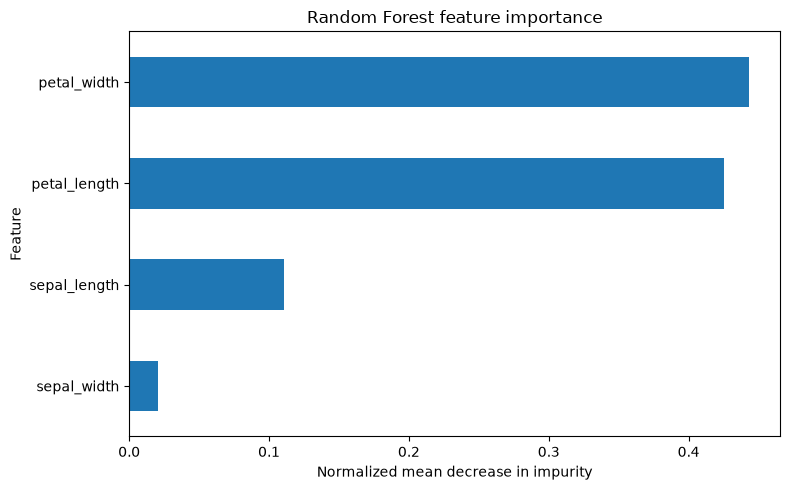

In [14]:
feature_importances = pd.Series(
    rf_model.feature_importances_,
    index=X.columns,
    name="Importance"
).sort_values(ascending=True)

display(feature_importances.sort_values(ascending=False).to_frame())

ax = feature_importances.plot(kind="barh", figsize=(8, 5), title="Random Forest feature importance")
ax.set_xlabel("Normalized mean decrease in impurity")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

### A caution about impurity-based importance

Impurity-based importance is useful for a quick model-specific summary, but it can favor variables with many possible split points and can divide importance among correlated predictors. It describes how the fitted forest used the available features; it is not a universal ranking of which variables matter in the real world.

A useful follow-up technique is **permutation importance**: shuffle one feature in the test data, measure how much model performance drops, and repeat for each feature. A large performance drop suggests the model relied on that feature for its predictions. Permutation importance answers a different question from impurity-based importance, so the rankings need not be identical.

## 8. Revision summary

| Idea | What to remember |
|---|---|
| Features `X` | Inputs used to make predictions |
| Target `y` | The answer the model learns to predict |
| Training set | Used by `.fit()` to learn patterns |
| Test set | Held aside to evaluate generalization |
| Fit | Learn model parameters/rules from training data |
| Impurity | How mixed the classes are within a node |
| Gini | $1-\sum p_k^2$; lower means purer |
| Entropy | $-\sum p_k\log_2(p_k)$; lower means purer |
| Split selection | Prefer a split with a large weighted impurity reduction |
| Overfitting | Learning training-specific detail that does not generalize well |
| Decision Tree | One set of hierarchical decision rules |
| Random Forest | Many randomized trees whose predictions are aggregated |
| Accuracy | Fraction of test predictions that are correct |
| Confusion matrix | Shows actual versus predicted classes and the error pattern |
| Feature importance | How much features contributed to impurity reduction in this fitted forest |

## Quick self-check

1. Why do we keep the test set separate while fitting the model?
2. What does a Gini impurity of zero tell you about a node?
3. Why does a decision tree use a weighted average of child-node impurities?
4. What are the two main sources of randomness in a Random Forest?
5. Why does high feature importance **not** prove causation?

**Suggested answers:** (1) to estimate performance on unseen observations; (2) all observations in the node belong to one class; (3) larger child nodes should contribute more to the split's overall impurity; (4) bootstrap samples and random feature subsets at splits; (5) importance describes the fitted model's use of a feature, not a causal relationship.

---

*Revision note:* Results can differ from the book because the split procedure, random-number generator, and tree implementation are not identical. Focus on the concepts and workflow rather than expecting exact matching outputs.